#### 1. 모델을 이용하여 학습/예측하기
- 수집된 데이터(가상의 데이터)
- 숭어의 길이, 무게
- 농어의 길이, 무게

In [14]:
import os
os.environ["PYTHONUTF8"] = "1"  # 이 두 줄을 맨 위에 추가합니다.

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier

In [16]:
# 1. 데이터 준비
# 숭어 데이터
mullet_length = [25, 26, 27, 28, 29, 30, 31, 32, 33, 34]
mullet_weight = [150, 160, 170, 180, 190, 200, 210, 220, 230, 240]

# 농어 데이터
bass_length = [35, 36, 37, 38, 39, 40, 41, 42, 43, 44]
bass_weight = [300, 320, 340, 360, 380, 400, 420, 440, 460, 480]

# 두 종류 데이터 합치기
length = mullet_length + bass_length
weight = mullet_weight + bass_weight

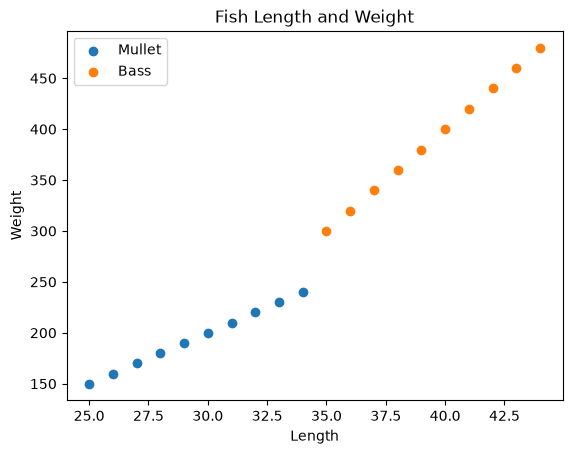

In [23]:
# 시각화 탐색 : 산점도
fig = plt.figure()
ax = fig.add_subplot(1, 1, 1)
ax.scatter(mullet_length, mullet_weight, label="Mullet")
ax.scatter(bass_length, bass_weight, label="Bass")
ax.set_xlabel("Length")
ax.set_ylabel("Weight")
ax.set_title("Fish Length and Weight")
ax.legend()
plt.show()

In [17]:
# 학습에 필요한 데이터셋 생성
# 입력 데이터
X = np.column_stack([length, weight])

# 정답 데이터
# 숭어 = 0, 농어 = 1
y = [0] * 10 + [1] * 10

print(X)
print(y)

[[ 25 150]
 [ 26 160]
 [ 27 170]
 [ 28 180]
 [ 29 190]
 [ 30 200]
 [ 31 210]
 [ 32 220]
 [ 33 230]
 [ 34 240]
 [ 35 300]
 [ 36 320]
 [ 37 340]
 [ 38 360]
 [ 39 380]
 [ 40 400]
 [ 41 420]
 [ 42 440]
 [ 43 460]
 [ 44 480]]
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


In [18]:
# KNN 모델 생성
knn = KNeighborsClassifier(n_neighbors=3)


In [20]:
# 모델 학습
knn.fit(X, y);

In [21]:
print(knn.classes_)

[0 1]


In [22]:
result = knn.predict([[30, 200]])

print(result)

[0]


In [7]:
# 예측
# 새로운 생선
new_fish = [[36, 350]]

prediction = knn.predict(new_fish)

print(prediction)

[1]


2) 실습용으로 데이터셋으로 분류모델 학습/예측 하기

- 수집된 데이터(fish.csv)
- Species — 생선 종류
- 정답(Label)으로 사용하는 변수다.
- 데이터에는 다음과 같은 종류가 있다.
- Bream, Roach, Whitefish, Parkki, Perch, Pike, Smelt
- (도미, 로치, 화이트피시, 파키, 퍼치, 파이크, 빙어)

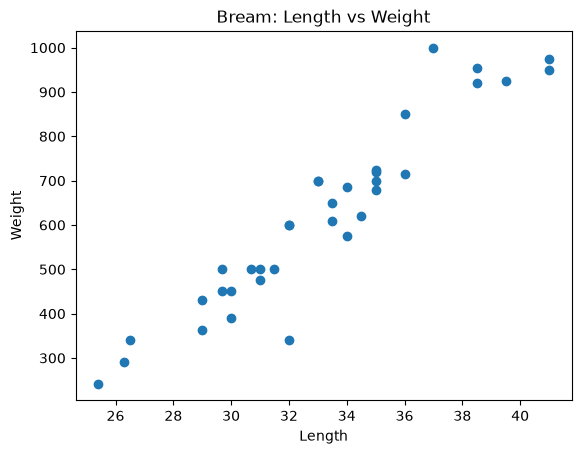

In [24]:
import pandas as pd
import matplotlib.pyplot as plt

# 데이터 불러오기
fish = pd.read_csv(
    "https://raw.githubusercontent.com/rickiepark/hg-mldl/master/fish.csv"
)

# Bream(브림:도미)만 선택
bream = fish[fish["Species"] == "Bream"]

# 산점도 그리기
plt.scatter(bream["Length"], bream["Weight"])

plt.xlabel("Length")
plt.ylabel("Weight")
plt.title("Bream: Length vs Weight")
plt.show()

In [25]:
# 테스트 데이터
X_test = [
    # Bream 30개
    [32.0, 340],
    [33.0, 360],
    [34.0, 390],
    [35.0, 420],
    [36.0, 450],
    [37.0, 480],
    [38.0, 510],
    [39.0, 540],
    [40.0, 570],
    [41.0, 600],
    [42.0, 630],
    [43.0, 660],
    [44.0, 690],
    [45.0, 720],
    [46.0, 750],
    [47.0, 780],
    [48.0, 810],
    [49.0, 840],
    [50.0, 870],
    [51.0, 900],
    [52.0, 920],
    [53.0, 940],
    [54.0, 960],
    [55.0, 980],
    [56.0, 1000],
    [57.0, 1020],
    [58.0, 1040],
    [59.0, 1060],
    [60.0, 1080],
    [61.0, 1100],

    # Smelt 15개
    [9.0, 6],
    [10.0, 7],
    [11.0, 8],
    [12.0, 9],
    [13.0, 10],
    [14.0, 11],
    [15.0, 12],
    [16.0, 13],
    [17.0, 14],
    [18.0, 15],
    [19.0, 16],
    [20.0, 17],
    [21.0, 18],
    [22.0, 19],
    [23.0, 20]
]

# 실제 정답
y_test = [1] * 30 + [0] * 15

In [27]:
from sklearn.metrics import accuracy_score

# 1 새로운 데이터 예측
prediction  = knn.predict(X_test )
print(prediction) 
print(accuracy_score(y_test, prediction))

[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0]
1.0


In [28]:
# 2 예측없이 바로 정확도
print(knn.score(X_test , y_test))

1.0
